# Generative AI Applications: Convolutional VAE on Fashion-MNIST

**Udacity Master's in AI Capstone, Project 5: Generative AI Applications**

## Task 1: Task definition and approach

### Goal
**Generate new, realistic clothing images (28x28 grayscale) and learn a smooth latent space of clothing styles.**

The model should (1) reconstruct real clothing images from a compact code, (2) produce *new* images when we sample random codes, and (3) organise the codes so that moving between two codes (for example from a sneaker to an ankle boot) gives a gradual, plausible change in style.

### Why a Variational Autoencoder (VAE)?
A VAE (Kingma & Welling, 2014) is an encoder-decoder network trained to maximise a lower bound on the data likelihood (the ELBO). The encoder maps an image to a Gaussian distribution over a latent code $z$, and the decoder maps $z$ back to an image. Training minimises a reconstruction term plus a KL-divergence term that pulls the encoder's distributions towards a standard normal prior $\mathcal{N}(0, I)$. The *reparameterisation trick* ($z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$) makes this sampling step differentiable (Kingma & Welling, 2014).

This fits the goal for four reasons:
- **Stable training:** a VAE minimises one well-defined loss with plain gradient descent. There is no adversarial min-max game, so it trains reliably on a CPU in a few minutes.
- **Explicit latent space:** every image gets a mean and variance in a 16-dimensional latent space. This is exactly what is needed for interpolation and for latent-space plots.
- **Reconstruction and sampling in one model:** the same decoder reconstructs test images (which can be measured) and generates new images from $z \sim \mathcal{N}(0, I)$.
- **Right size for the data:** 28x28 grayscale images are small enough that a compact convolutional VAE can model them well.

### Data source
| Item | Details |
|---|---|
| Name | **Fashion-MNIST** (Xiao et al., 2017) |
| URL | https://github.com/zalandoresearch/fashion-mnist |
| License | MIT License (see `LICENSE` in the repository) |
| Content | 70,000 grayscale 28x28 images of Zalando fashion products, 10 classes (60,000 train / 10,000 test) |
| Origin | **Real, human-made product photos** from Zalando's online catalogue, converted to 28x28 grayscale by the dataset authors. The images are **not synthetic and not AI-generated**. |
| Access | Downloaded automatically by `torchvision.datasets.FashionMNIST(root="./data", download=True)` the first time the notebook runs (about 30 MB). No account or API key is needed. |
| Use | Used here only for **academic, non-commercial** coursework (Udacity capstone). |

### Notebook outline
1. Setup (imports, fixed seeds, device)
2. Load and inspect the data (Task 2)
3. Implement and train the convolutional VAE (Task 3)
4. Generate and evaluate outputs (Task 4): reconstructions, random samples, interpolation, per-class error, memorisation check
5. Optional extras: beta-VAE comparison and a t-SNE plot of the latent space
6. Summary (Task 5)

## 0. Setup
All random number generators (`random`, `numpy`, `torch`) use one fixed seed, so a rerun gives the same split, training run, samples and figures. The notebook uses CUDA if a GPU is available and the CPU otherwise.

In [1]:
import os
import json
import time
import random
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import sklearn
from sklearn.manifold import TSNE

# ---- Reproducibility: fixed seeds for every random number generator ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR = "./data", "figures", "models", "results"
for d in (DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"Python      {platform.python_version()}")
for lib in (np, pd, matplotlib, sns, torch, torchvision, sklearn):
    print(f"{lib.__name__:<12}{lib.__version__}")
print(f"device      {device}")

Python      3.11.0
numpy       2.4.6
pandas      3.1.0
matplotlib  3.11.2
seaborn     0.13.2
torch       2.14.1+cpu
torchvision 0.29.1+cpu
sklearn     1.9.1
device      cpu


## Task 2: Load and inspect the data
`transforms.ToTensor()` turns each 28x28 `uint8` image into a `float32` tensor of shape `(1, 28, 28)` with values in $[0, 1]$.

In [2]:
to_tensor = transforms.ToTensor()
train_full = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=to_tensor)
test_set = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=to_tensor)
CLASS_NAMES = train_full.classes

print(f"Train images: {len(train_full):,}   Test images: {len(test_set):,}   Total: {len(train_full) + len(test_set):,}")
print(f"Raw train array : shape={tuple(train_full.data.shape)}, dtype={train_full.data.dtype}, "
      f"min={train_full.data.min().item()}, max={train_full.data.max().item()}")
print(f"Raw test array  : shape={tuple(test_set.data.shape)}, dtype={test_set.data.dtype}, "
      f"min={test_set.data.min().item()}, max={test_set.data.max().item()}")
x0, y0 = train_full[0]
print(f"After ToTensor  : shape={tuple(x0.shape)}, dtype={x0.dtype}, min={x0.min().item():.1f}, max={x0.max().item():.1f}")
print(f"Mean pixel value (train, scaled): {train_full.data.float().div(255).mean().item():.4f}")
print("\nClasses:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i}: {name}")

Train images: 60,000   Test images: 10,000   Total: 70,000
Raw train array : shape=(60000, 28, 28), dtype=torch.uint8, min=0, max=255
Raw test array  : shape=(10000, 28, 28), dtype=torch.uint8, min=0, max=255
After ToTensor  : shape=(1, 28, 28), dtype=torch.float32, min=0.0, max=1.0
Mean pixel value (train, scaled): 0.2860

Classes:
  0: T-shirt/top
  1: Trouser
  2: Pullover
  3: Dress
  4: Coat
  5: Sandal
  6: Shirt
  7: Sneaker
  8: Bag
  9: Ankle boot


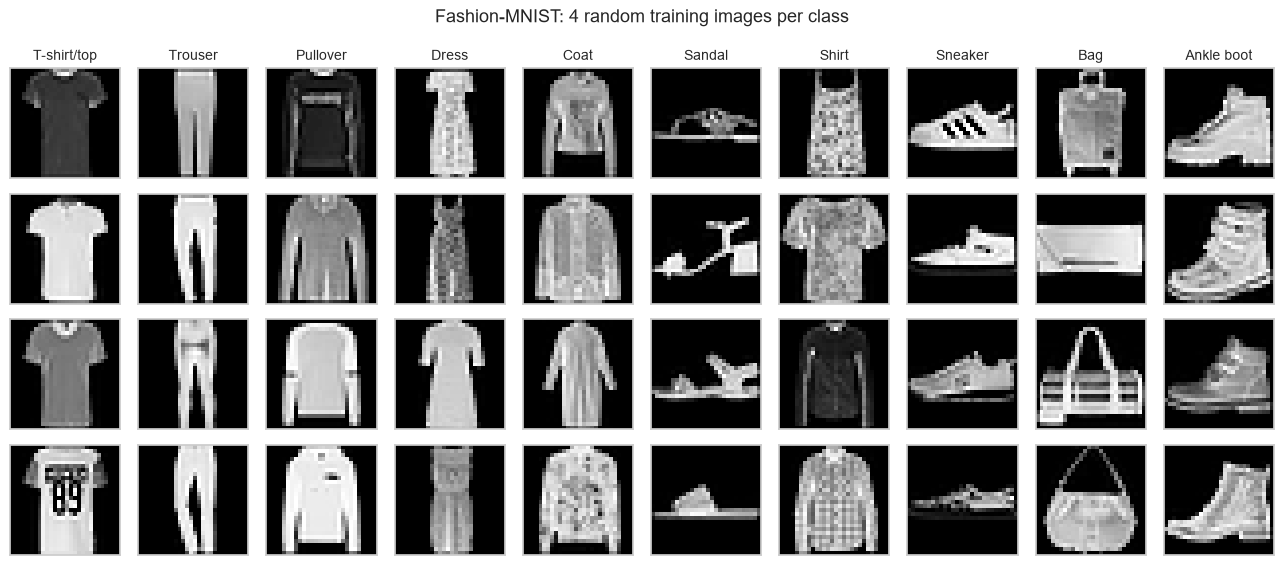

In [3]:
# Representative samples: 4 random training images per class (40 images)
rng = np.random.default_rng(SEED)
train_labels = train_full.targets.numpy()
test_labels = test_set.targets.numpy()

fig, axes = plt.subplots(4, 10, figsize=(13, 5.8))
for c in range(10):
    idx = rng.choice(np.where(train_labels == c)[0], size=4, replace=False)
    for r, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(train_full.data[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=10)
fig.suptitle("Fashion-MNIST: 4 random training images per class", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/data_samples.png", dpi=150, bbox_inches="tight")
plt.show()

      class  train  test  total
T-shirt/top   6000  1000   7000
    Trouser   6000  1000   7000
   Pullover   6000  1000   7000
      Dress   6000  1000   7000
       Coat   6000  1000   7000
     Sandal   6000  1000   7000
      Shirt   6000  1000   7000
    Sneaker   6000  1000   7000
        Bag   6000  1000   7000
 Ankle boot   6000  1000   7000


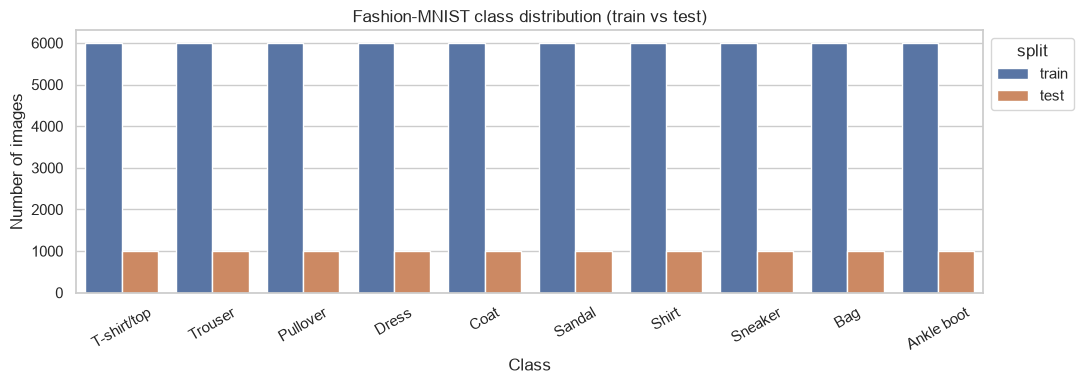

In [4]:
# Class balance: count table (pandas) and bar plot (seaborn)
counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(train_labels, minlength=10),
    "test": np.bincount(test_labels, minlength=10),
})
counts["total"] = counts["train"] + counts["test"]
print(counts.to_string(index=False))

long = counts.melt(id_vars="class", value_vars=["train", "test"], var_name="split", value_name="count")
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=long, x="class", y="count", hue="split", ax=ax)
ax.set_title("Fashion-MNIST class distribution (train vs test)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.legend(title="split", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Observations and preprocessing notes
- **Balanced classes:** every class has exactly 6,000 training and 1,000 test images, so no re-weighting or re-sampling is needed.
- **Inspection of the samples:** items are centred on a black background. Footwear (sandal, sneaker, ankle boot) and trousers have very distinct shapes. T-shirt/top, pullover, coat and shirt share almost the same silhouette and differ mainly in small details (collars, buttons, zips, sleeve length). Bags vary a lot in shape and handles. These visual overlaps are where we expect a VAE to blend classes.
- **Scaling:** `ToTensor()` divides by 255, so pixels are in $[0, 1]$. This is required because the reconstruction loss is binary cross-entropy (BCE), which treats each pixel intensity as a Bernoulli probability and needs targets in $[0, 1]$. No mean/std normalisation is applied, because that would push values outside $[0, 1]$.
- **No augmentation:** the goal is to model the real catalogue images as they are. Flips or rotations would create poses that are not in the data (for example upside-down shoes).
- **Validation split:** 5,000 images are held out at random (fixed seed) from the 60,000 training images. This gives **55,000 train / 5,000 validation / 10,000 test**. The validation set is only used to monitor over-fitting. The test set is only used for the final evaluation in Task 4.
- **Speed:** for fast training on a CPU, the images are kept in memory as one tensor. The values are exactly the same as `ToTensor()` gives (checked with an `assert` below).

In [5]:
# In-memory tensors (identical to ToTensor output) and a fixed 55k / 5k train/validation split
X_train_full = train_full.data.unsqueeze(1).float().div(255.0)
y_train_full = train_full.targets.clone()
X_test = test_set.data.unsqueeze(1).float().div(255.0)
y_test = test_set.targets.clone()
assert torch.equal(X_train_full[0], train_full[0][0]) and torch.equal(X_test[0], test_set[0][0])

N_VAL = 5000
perm = torch.randperm(len(X_train_full), generator=torch.Generator().manual_seed(SEED))
val_idx, tr_idx = perm[:N_VAL], perm[N_VAL:]
X_tr, y_tr = X_train_full[tr_idx], y_train_full[tr_idx]
X_val, y_val = X_train_full[val_idx], y_train_full[val_idx]

BATCH_SIZE = 128
train_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True, generator=train_gen)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=512, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=512, shuffle=False)

print(f"train: {tuple(X_tr.shape)}  val: {tuple(X_val.shape)}  test: {tuple(X_test.shape)}")
print(f"train batches per epoch: {len(train_loader)} (batch size {BATCH_SIZE})")

train: (55000, 1, 28, 28)  val: (5000, 1, 28, 28)  test: (10000, 1, 28, 28)
train batches per epoch: 430 (batch size 128)


## Task 3: Implement and train the VAE

### Architecture
```
Encoder:  x (1x28x28)
          -> Conv2d(1->32, k4, s2, p1) + ReLU     -> 32x14x14
          -> Conv2d(32->64, k4, s2, p1) + ReLU    -> 64x7x7
          -> Flatten (3136) -> Linear(3136->256) + ReLU
          -> fc_mu: Linear(256->16),  fc_logvar: Linear(256->16)
Sampling: z = mu + exp(0.5 * logvar) * eps,  eps ~ N(0, I)      (reparameterisation trick)
Decoder:  z (16) -> Linear(16->256) + ReLU -> Linear(256->3136) + ReLU -> reshape 64x7x7
          -> ConvTranspose2d(64->32, k4, s2, p1) + ReLU -> 32x14x14
          -> ConvTranspose2d(32->1,  k4, s2, p1) + Sigmoid -> 1x28x28 (pixel probabilities)
```

### Design choices
| Choice | Value | Reason |
|---|---|---|
| Encoder/decoder | Convolutional (stride-2 conv / transposed conv) | Convolutions share weights across positions and capture local edges and textures (collars, straps, soles). An MLP on 784 flattened pixels ignores the 2-D structure and needs more parameters per layer. Stride 2 halves resolution (28 -> 14 -> 7) without pooling layers. |
| Latent size | `latent_dim = 16` | A 2-D code is easy to plot but leaves little room for shape, sleeve length, heel height and brightness. 16 dimensions give the model room for these factors, and the code is still small enough for the KL term to keep the space smooth for sampling and interpolation. The KL-per-dimension diagnostic in Task 4 checks how many dimensions the model really uses. |
| Output | Sigmoid | Each output pixel is the mean of a Bernoulli distribution, in $[0, 1]$. |
| Reconstruction loss | Binary cross-entropy, summed over the 784 pixels | This is the negative log-likelihood under the Bernoulli decoder used for binary-like image data (Kingma & Welling, 2014). Fashion-MNIST pixels are mostly near 0 (background) or bright, so this fits well. |
| Regulariser | KL$(q(z\mid x)\,\|\,\mathcal{N}(0,I))$, closed form $-\tfrac12\sum(1+\log\sigma^2-\mu^2-\sigma^2)$ | Together with BCE this gives the negative ELBO (Kingma & Welling, 2014). It makes $z \sim \mathcal{N}(0, I)$ decode to realistic images. Weight $\beta = 1$ for the main model. |
| Loss scale | Summed per image, averaged over the batch | So the numbers below are "nats per image" and the two terms are on comparable scales. |
| Optimiser | Adam, `lr = 1e-3` | Adam adapts the step size for each parameter, which handles the very different gradient scales of the BCE and KL terms. The original VAE was also trained with an adaptive-step-size optimiser (Kingma & Welling, 2014). 1e-3 is Adam's default learning rate in PyTorch, and the loss curves below show it is stable here. |
| Batch size | 128 | 430 updates per epoch. This gives stable gradient estimates and fast CPU epochs. |
| Epochs | 25 | Enough for the validation loss to flatten (see the loss curves) while keeping CPU training well under 15 minutes. |

In [6]:
class ConvVAE(nn.Module):
    # Convolutional VAE: conv encoder -> (mu, logvar) -> reparameterised z -> transposed-conv decoder

    def __init__(self, latent_dim=16, hidden_dim=256):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # 32 x 14 x 14
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 64 x 7 x 7
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 64 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # 32 x 14 x 14
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),   # 1 x 28 x 28
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


LATENT_DIM = 16
torch.manual_seed(SEED)
model = ConvVAE(latent_dim=LATENT_DIM).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTotal parameters: {n_params:,}  (trainable: {n_trainable:,})")

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=256, bias=True)
    (6): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=3136, bias=True)
    (3): ReLU()
    (4): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (5): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): ReLU()
    (7): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Total parameters: 1,688,289  (trainable: 1,688,289)


In [7]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    # Negative ELBO per image: BCE summed over pixels + beta * KL(q(z|x) || N(0, I)), averaged over the batch
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + beta * kl, recon, kl


def run_epoch(model, loader, optimizer=None, beta=1.0):
    # One pass over `loader`; trains if an optimizer is given, otherwise evaluates. Returns mean (total, recon, KL) per image.
    training = optimizer is not None
    model.train(training)
    sums, n = np.zeros(3), 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            sums += np.array([loss.item(), recon.item(), kl.item()]) * x.size(0)
            n += x.size(0)
    return sums / n


def fit(model, epochs, beta=1.0, lr=1e-3, label="VAE"):
    # Adam training loop that logs train and validation losses every epoch
    train_gen.manual_seed(SEED)  # same mini-batch order for every model trained with fit()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    rows, t0 = [], time.perf_counter()
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, optimizer, beta)
        va = run_epoch(model, val_loader, None, beta)
        rows.append({"epoch": epoch,
                     "train_total": tr[0], "train_recon": tr[1], "train_kl": tr[2],
                     "val_total": va[0], "val_recon": va[1], "val_kl": va[2]})
        print(f"[{label}] epoch {epoch:2d}/{epochs} | train total {tr[0]:7.2f} (recon {tr[1]:7.2f}, KL {tr[2]:5.2f}) "
              f"| val total {va[0]:7.2f} (recon {va[1]:7.2f}, KL {va[2]:5.2f}) | {time.perf_counter() - t0:5.0f}s")
    return pd.DataFrame(rows), time.perf_counter() - t0

In [8]:
EPOCHS = 25
LR = 1e-3
BETA = 1.0

torch.manual_seed(SEED)
history, train_seconds = fit(model, EPOCHS, beta=BETA, lr=LR, label="VAE")
print(f"\nTraining time: {train_seconds / 60:.1f} min on {device}")
history.to_csv(f"{RESULTS_DIR}/training_history.csv", index=False)
print(history.round(2).to_string(index=False))

[VAE] epoch  1/25 | train total  280.68 (recon  269.13, KL 11.55) | val total  254.38 (recon  241.55, KL 12.83) |     5s


[VAE] epoch  2/25 | train total  249.54 (recon  236.71, KL 12.83) | val total  246.83 (recon  233.89, KL 12.94) |    10s


[VAE] epoch  3/25 | train total  244.96 (recon  231.84, KL 13.12) | val total  243.84 (recon  230.09, KL 13.74) |    16s


[VAE] epoch  4/25 | train total  242.64 (recon  229.27, KL 13.38) | val total  242.02 (recon  228.12, KL 13.91) |    22s


[VAE] epoch  5/25 | train total  241.18 (recon  227.66, KL 13.52) | val total  240.90 (recon  227.02, KL 13.88) |    28s


...

[VAE] epoch 21/25 | train total  235.77 (recon  221.24, KL 14.53) | val total  236.63 (recon  222.25, KL 14.38) |   122s


[VAE] epoch 22/25 | train total  235.65 (recon  221.10, KL 14.55) | val total  236.66 (recon  222.05, KL 14.60) |   128s


[VAE] epoch 23/25 | train total  235.52 (recon  220.95, KL 14.57) | val total  236.38 (recon  221.89, KL 14.49) |   134s


[VAE] epoch 24/25 | train total  235.39 (recon  220.82, KL 14.57) | val total  236.27 (recon  221.50, KL 14.77) |   140s


[VAE] epoch 25/25 | train total  235.30 (recon  220.71, KL 14.59) | val total  236.40 (recon  221.60, KL 14.80) |   146s

Training time: 2.4 min on cpu
 epoch  train_total  train_recon  train_kl  val_total  val_recon  val_kl
     1       280.68       269.13     11.55     254.38     241.55   12.83
     2       249.54       236.71     12.83     246.83     233.89   12.94
     3       244.96       231.84     13.12     243.84     230.09   13.74
     4       242.64       229.27     13.38     242.02     228.12   13.91
     5       241.18       227.66     13.52     240.90     227.02   13.88
     6       240.21       226.58     13.64     240.20     226.25   13.95
     7       239.53       225.77     13.76     239.68     226.06   13.62
     8       238.96       225.09     13.87     239.27     225.65   13.63
     9       238.46       224.51     13.95     239.08     225.35   13.73
    10       238.04       224.03     14.02     238.49     224.60   13.88
    11       237.70       223.60     14.10   

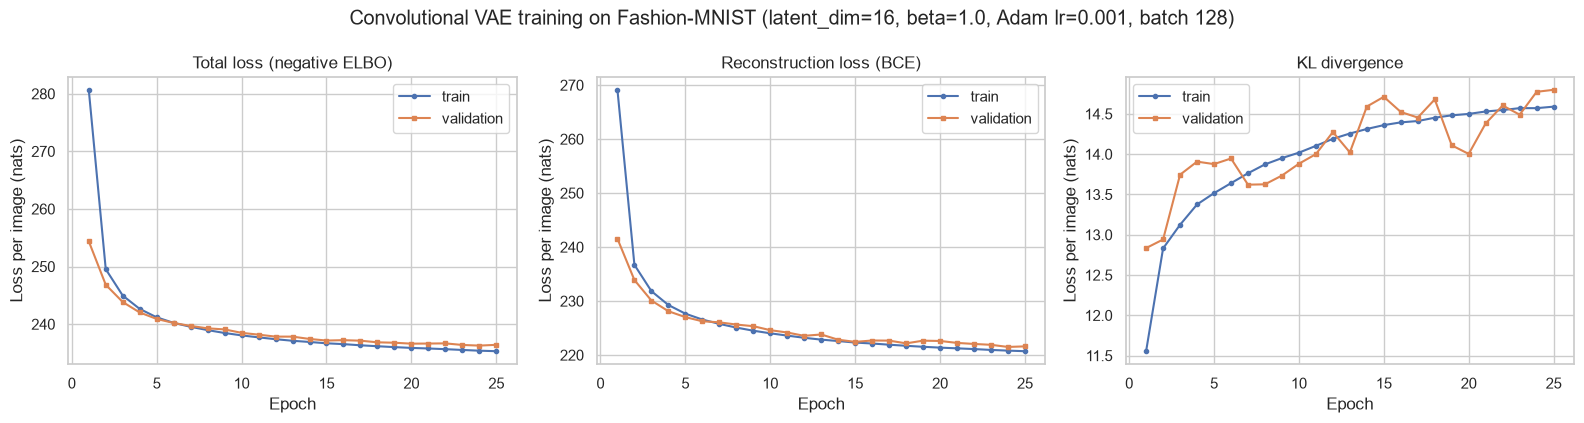

Epoch 1  -> train total 280.68, val total 254.38
Epoch 25 -> train total 235.30, val total 236.40
Last-5-epoch improvement in val total: 0.21 nats
Val - train gap at the end: 1.10 nats


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
panels = [("total", "Total loss (negative ELBO)"), ("recon", "Reconstruction loss (BCE)"), ("kl", "KL divergence")]
for ax, (key, title) in zip(axes, panels):
    ax.plot(history["epoch"], history[f"train_{key}"], marker="o", ms=3, label="train")
    ax.plot(history["epoch"], history[f"val_{key}"], marker="s", ms=3, label="validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss per image (nats)")
    ax.legend()
fig.suptitle(f"Convolutional VAE training on Fashion-MNIST (latent_dim={LATENT_DIM}, beta={BETA}, Adam lr={LR}, batch {BATCH_SIZE})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

first, last = history.iloc[0], history.iloc[-1]
print(f"Epoch 1  -> train total {first.train_total:.2f}, val total {first.val_total:.2f}")
print(f"Epoch {EPOCHS} -> train total {last.train_total:.2f}, val total {last.val_total:.2f}")
print(f"Last-5-epoch improvement in val total: {history.val_total.iloc[-6] - last.val_total:.2f} nats")
print(f"Val - train gap at the end: {last.val_total - last.train_total:.2f} nats")


### Training diagnostics: what the loss curves show
- **Stable convergence, no divergence:** the validation negative ELBO falls from **254.38** (epoch 1) to **236.40** nats/image (epoch 25). Over the last 5 epochs it improves by only **0.21** nats, so the model has essentially converged at 25 epochs. CPU training took about **2.4 minutes** (printed above; the time varies with the machine and its load), well under the 15-minute budget, so the epoch count did not need to be reduced.
- **No over-fitting:** the final validation loss is only **1.10** nats above the training loss, and both curves keep decreasing together. In epoch 1 the training loss (280.68) is *higher* than the validation loss (254.38). This is because the training number is averaged while the weights are still improving during the epoch, whereas validation is measured at the end of the epoch.
- **Reconstruction vs KL trade-off:** the BCE term falls (val 241.55 → 221.60) while the KL term *rises* (val 12.83 → 14.80). The encoder gradually puts more information into $z$ (higher KL) because this buys better reconstructions. This trade-off between the two terms is the central training challenge of a VAE (Kingma & Welling, 2014). The validation KL is noisier than the training KL (e.g. 14.71 at epoch 15 → 14.00 at epoch 20), because it is a single-sample estimate on only 5,000 images.
- **Partial posterior collapse:** the KL-per-dimension diagnostic in Task 4 shows that only **9 of the 16** latent dimensions carry information. The other 7 stay at the prior (KL ≈ 0). For this data and loss, 16 dimensions are more than the model needs.


In [10]:
MODEL_PATH = f"{MODEL_DIR}/vae_fashionmnist.pt"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Saved weights to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

# Reload check: the saved file gives a working model
reloaded = ConvVAE(latent_dim=LATENT_DIM).to(device)
reloaded.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
print("Reload OK")

Saved weights to models/vae_fashionmnist.pt (6.8 MB)
Reload OK


## Task 4: Generate and evaluate outputs
All evaluation uses the **test set** (10,000 images never used for training or model selection). For reconstructions we decode the encoder mean $\mu$, which gives deterministic outputs. We measure:
- **Test negative ELBO, BCE and KL** (the same loss as in training),
- **Reconstruction MSE** per image (mean squared pixel error, scale $[0,1]$), overall and per class.

In [11]:
model.eval()


@torch.no_grad()
def recon_errors(model, X):
    # Deterministic reconstructions (decode mu); returns per-image MSE and BCE (summed over pixels)
    mses, bces = [], []
    for i in range(0, len(X), 1000):
        x = X[i:i + 1000].to(device)
        mu, _ = model.encode(x)
        x_hat = model.decode(mu)
        mses.append(((x_hat - x) ** 2).mean(dim=(1, 2, 3)).cpu())
        bces.append(F.binary_cross_entropy(x_hat, x, reduction="none").sum(dim=(1, 2, 3)).cpu())
    return torch.cat(mses).numpy(), torch.cat(bces).numpy()


torch.manual_seed(SEED)
test_total, test_recon, test_kl = run_epoch(model, test_loader)
test_mse, test_bce = recon_errors(model, X_test)
print(f"Test negative ELBO: {test_total:.2f} nats/image (BCE {test_recon:.2f} + KL {test_kl:.2f})")
print(f"Test reconstruction MSE (decode mu): {test_mse.mean():.4f}   |   BCE (decode mu): {test_bce.mean():.2f} nats/image")

Test negative ELBO: 237.83 nats/image (BCE 223.07 + KL 14.76)
Test reconstruction MSE (decode mu): 0.0124   |   BCE (decode mu): 219.22 nats/image


Active latent dimensions (mean KL > 0.01 nats): 9 of 16
KL per dimension, sorted: [2.700000047683716, 2.4700000286102295, 1.9199999570846558, 1.8600000143051147, 1.8200000524520874, 1.6100000143051147, 1.059999942779541, 0.8100000023841858, 0.5199999809265137, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


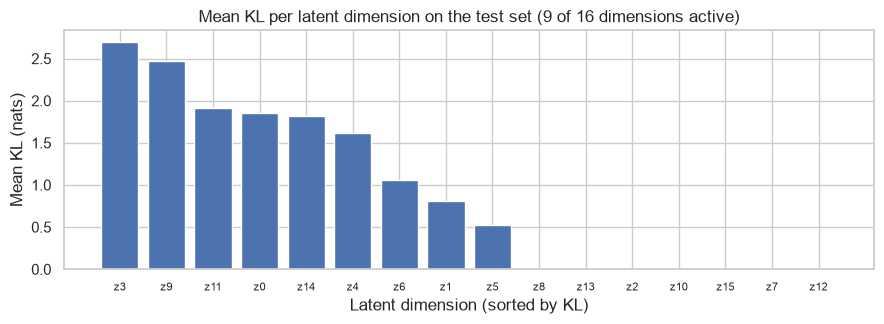

In [12]:
# Diagnostic: how many latent dimensions does the model actually use? (mean KL per dimension on the test set)
@torch.no_grad()
def kl_per_dim(model, X):
    mu, logvar = model.encode(X.to(device))
    return (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).mean(dim=0).cpu().numpy()


kl_dim = kl_per_dim(model, X_test)
active_dims = int((kl_dim > 0.01).sum())
order = np.argsort(-kl_dim)
print(f"Active latent dimensions (mean KL > 0.01 nats): {active_dims} of {LATENT_DIM}")
print("KL per dimension, sorted:", np.round(kl_dim[order], 2).tolist())

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(1, LATENT_DIM + 1), kl_dim[order], color="#4C72B0")
ax.set_xticks(range(1, LATENT_DIM + 1), [f"z{j}" for j in order], fontsize=8)
ax.set_title(f"Mean KL per latent dimension on the test set ({active_dims} of {LATENT_DIM} dimensions active)")
ax.set_xlabel("Latent dimension (sorted by KL)")
ax.set_ylabel("Mean KL (nats)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/latent_kl_per_dim.png", dpi=150, bbox_inches="tight")
plt.show()

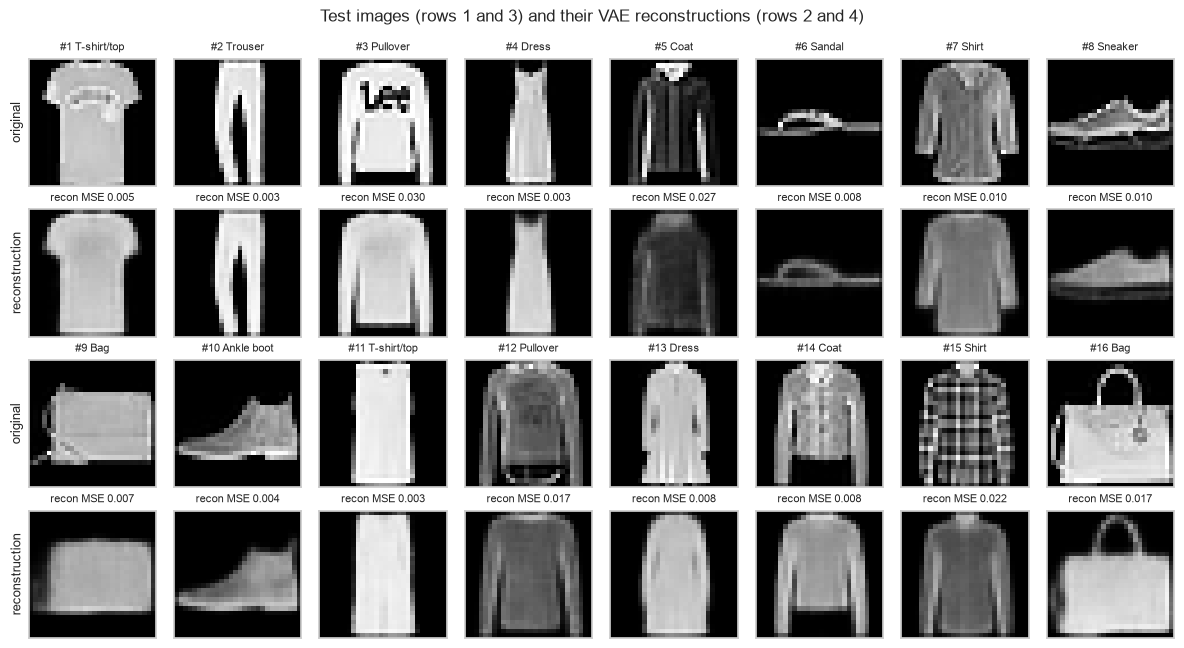

In [13]:
# 16 test images: the first test image of every class + a second one for the six hardest-looking classes
pick = [int(np.where(test_labels == c)[0][0]) for c in range(10)]
pick += [int(np.where(test_labels == c)[0][1]) for c in [0, 2, 3, 4, 6, 8]]
with torch.no_grad():
    xs = X_test[pick].to(device)
    recons = model.decode(model.encode(xs)[0]).cpu()

fig, axes = plt.subplots(4, 8, figsize=(12, 6.6))
for k in range(16):
    r, c = 2 * (k // 8), k % 8
    axes[r, c].imshow(X_test[pick[k], 0], cmap="gray", vmin=0, vmax=1)
    axes[r, c].set_title(f"#{k + 1} {CLASS_NAMES[test_labels[pick[k]]]}", fontsize=8)
    axes[r + 1, c].imshow(recons[k, 0], cmap="gray", vmin=0, vmax=1)
    axes[r + 1, c].set_title(f"recon MSE {test_mse[pick[k]]:.3f}", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
for r, lab in enumerate(["original", "reconstruction", "original", "reconstruction"]):
    axes[r, 0].set_ylabel(lab, fontsize=9)
fig.suptitle("Test images (rows 1 and 3) and their VAE reconstructions (rows 2 and 4)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

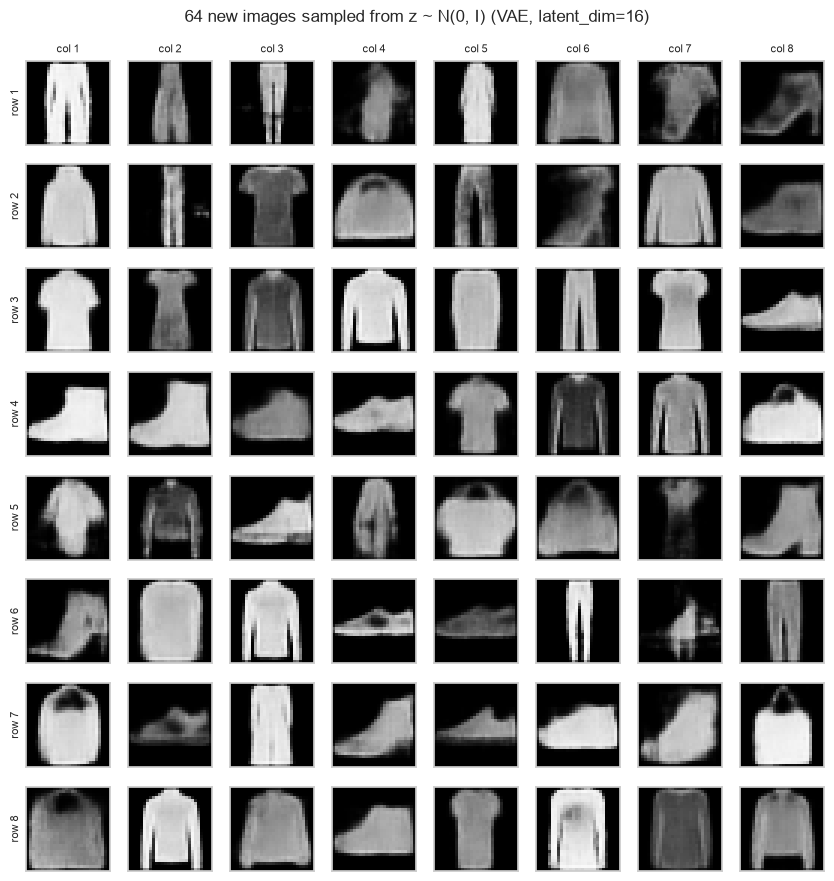

In [14]:
# 64 brand-new images from z ~ N(0, I)
torch.manual_seed(SEED)
z_samples = torch.randn(64, LATENT_DIM, device=device)
with torch.no_grad():
    samples = model.decode(z_samples).cpu()


def plot_grid(imgs, title, path=None, ax_grid=None):
    # 8x8 grid with row/column numbers so individual samples can be referenced as (row, col)
    fig, axes = plt.subplots(8, 8, figsize=(8.5, 9))
    for k in range(64):
        ax = axes[k // 8, k % 8]
        ax.imshow(imgs[k, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if k // 8 == 0:
            ax.set_title(f"col {k % 8 + 1}", fontsize=8)
        if k % 8 == 0:
            ax.set_ylabel(f"row {k // 8 + 1}", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


plot_grid(samples, "64 new images sampled from z ~ N(0, I) (VAE, latent_dim=16)", f"{FIG_DIR}/generated_samples.png")

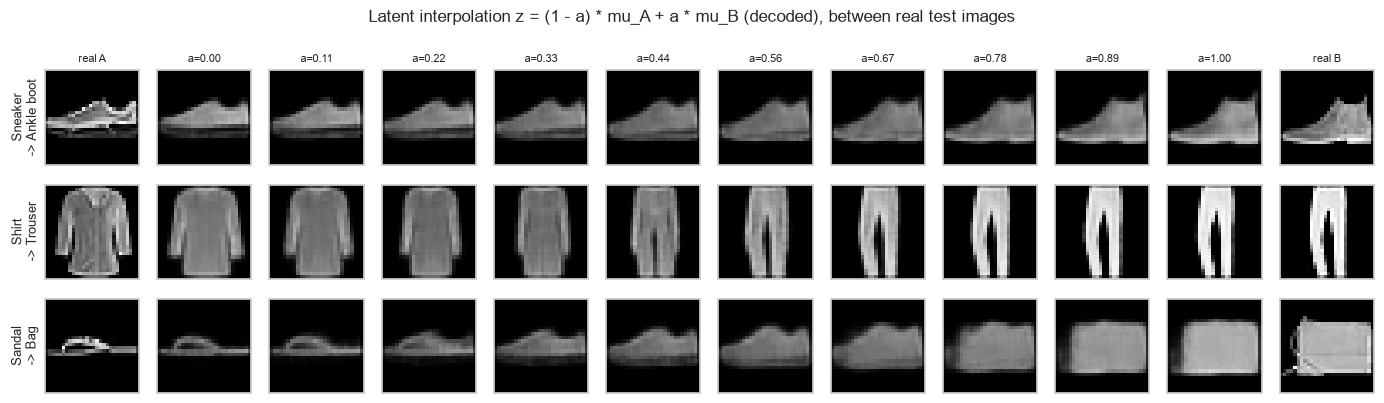

In [15]:
# Latent interpolation between two real test images of different classes (linear path between encoder means)
pairs = [("Sneaker", "Ankle boot"), ("Shirt", "Trouser"), ("Sandal", "Bag")]
alphas = np.linspace(0, 1, 10)
fig, axes = plt.subplots(len(pairs), len(alphas) + 2, figsize=(14, 4.2))
for r, (a, b) in enumerate(pairs):
    ia = int(np.where(test_labels == CLASS_NAMES.index(a))[0][0])
    ib = int(np.where(test_labels == CLASS_NAMES.index(b))[0][0])
    with torch.no_grad():
        mu_a = model.encode(X_test[ia:ia + 1].to(device))[0]
        mu_b = model.encode(X_test[ib:ib + 1].to(device))[0]
        path = torch.cat([(1 - t) * mu_a + t * mu_b for t in alphas])
        frames = model.decode(path).cpu()
    axes[r, 0].imshow(X_test[ia, 0], cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_ylabel(f"{a}\n-> {b}", fontsize=9)
    axes[r, -1].imshow(X_test[ib, 0], cmap="gray", vmin=0, vmax=1)
    for j in range(len(alphas)):
        axes[r, j + 1].imshow(frames[j, 0], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, j + 1].set_title(f"a={alphas[j]:.2f}", fontsize=8)
    if r == 0:
        axes[r, 0].set_title("real A", fontsize=8)
        axes[r, -1].set_title("real B", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Latent interpolation z = (1 - a) * mu_A + a * mu_B (decoded), between real test images", fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/latent_interpolation.png", dpi=150, bbox_inches="tight")
plt.show()

                mse         bce
class                          
Sandal       0.0193  161.109406
Bag          0.0182  270.812408
Shirt        0.0122  278.333801
Pullover     0.0119  283.667206
T-shirt/top  0.0116  255.306900
Ankle boot   0.0116  203.496002
Dress        0.0114  185.928207
Coat         0.0110  254.476395
Sneaker      0.0106  150.807404
Trouser      0.0062  148.276001

Worst class: Sandal (MSE 0.0193); best class: Trouser (MSE 0.0062); ratio 3.1x


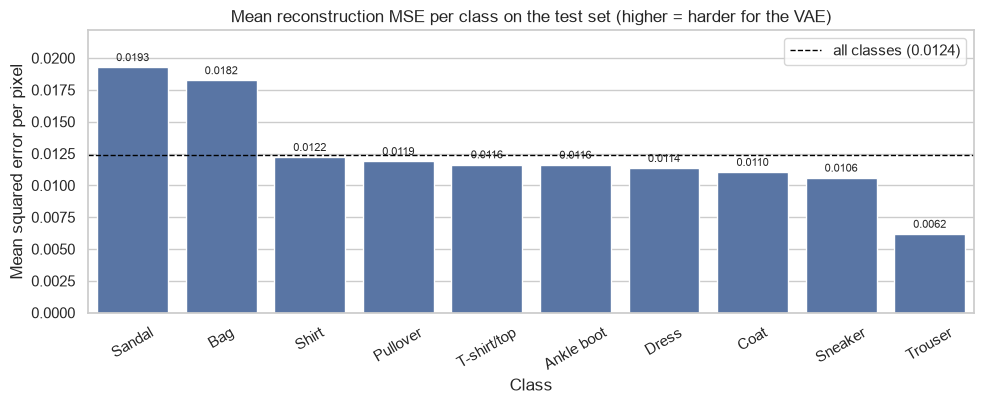

In [16]:
# Per-class reconstruction error on the full test set
per_class = (pd.DataFrame({"class": [CLASS_NAMES[i] for i in test_labels], "mse": test_mse, "bce": test_bce})
             .groupby("class")[["mse", "bce"]].mean()
             .sort_values("mse", ascending=False))
print(per_class.round(4).to_string())
print(f"\nWorst class: {per_class.index[0]} (MSE {per_class.mse.iloc[0]:.4f}); "
      f"best class: {per_class.index[-1]} (MSE {per_class.mse.iloc[-1]:.4f}); "
      f"ratio {per_class.mse.iloc[0] / per_class.mse.iloc[-1]:.1f}x")

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(x=per_class.index, y=per_class.mse.values, color="#4C72B0", ax=ax)
ax.axhline(test_mse.mean(), color="black", ls="--", lw=1, label=f"all classes ({test_mse.mean():.4f})")
for i, v in enumerate(per_class.mse.values):
    ax.text(i, v + 0.0003, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, per_class.mse.max() * 1.15)
ax.set_title("Mean reconstruction MSE per class on the test set (higher = harder for the VAE)")
ax.set_xlabel("Class")
ax.set_ylabel("Mean squared error per pixel")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/per_class_error.png", dpi=150, bbox_inches="tight")
plt.show()

### Memorisation check (nearest training neighbours)
A generative model that copies its training images would raise creative-ownership concerns (Carlini et al., 2023). For each generated sample we find the **closest of the 60,000 training images** by pixel L2 distance. As a reference point, we do the same for 64 real **test** images. These are real, unseen photos, so their distance to the nearest training image shows how close two *different* real products can be. If generated samples were much closer to their neighbours than real test images are, that would suggest copying. We also use the class of the nearest neighbour as a rough label for each generated sample, to check *diversity* (do the 64 samples cover all 10 classes?).

Generated samples -> nearest train image: mean L2 3.35, min 1.87, max 5.84
Real test images  -> nearest train image: mean L2 3.34, min 1.67, max 5.81


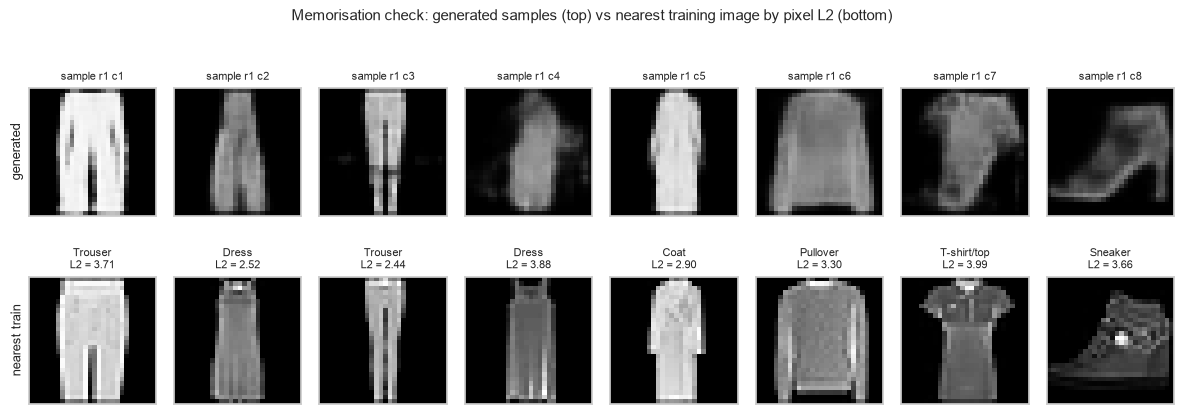


Nearest-neighbour class of each generated sample (same layout as the 8x8 grid):
      col 1  col 2  col 3  col 4  col 5  col 6  col 7 col 8
row 1  Trou  Dress   Trou  Dress   Coat   Pull    Tee  Snkr
row 2  Coat  Dress    Tee    Bag   Trou    Tee  Shirt  Boot
row 3   Tee  Dress  Shirt   Coat   Coat   Trou    Tee  Snkr
row 4  Boot   Boot   Snkr   Snkr    Tee  Shirt  Shirt   Bag
row 5  Coat   Coat   Snkr   Coat    Bag    Bag  Shirt  Boot
row 6  Boot   Pull  Shirt   Snkr   Snkr   Trou   Snkr  Trou
row 7   Bag   Sand    Tee   Boot   Snkr   Boot   Boot   Bag
row 8   Bag   Coat   Coat   Boot  Dress  Dress   Pull  Coat

Samples per (nearest-neighbour) class:
T-shirt/top     7
Trouser         6
Pullover        3
Dress           6
Coat           10
Sandal          1
Shirt           6
Sneaker         9
Bag             7
Ankle boot      9
Classes covered: 10/10


In [17]:
X_train_flat = X_train_full.view(len(X_train_full), -1).to(device)


@torch.no_grad()
def nearest_train(imgs):
    # Index and L2 distance of the nearest training image for each image in `imgs`
    d = torch.cdist(imgs.view(len(imgs), -1).to(device), X_train_flat)
    dist, idx = d.min(dim=1)
    return idx.cpu().numpy(), dist.cpu().numpy()


nn_idx, nn_dist = nearest_train(samples)
ref_idx = np.random.default_rng(SEED).choice(len(X_test), size=64, replace=False)
_, ref_dist = nearest_train(X_test[ref_idx])
print(f"Generated samples -> nearest train image: mean L2 {nn_dist.mean():.2f}, min {nn_dist.min():.2f}, max {nn_dist.max():.2f}")
print(f"Real test images  -> nearest train image: mean L2 {ref_dist.mean():.2f}, min {ref_dist.min():.2f}, max {ref_dist.max():.2f}")

# Figure: first 8 samples (row 1 of the 8x8 grid) next to their nearest training image
fig, axes = plt.subplots(2, 8, figsize=(12, 4.6))
for k in range(8):
    axes[0, k].imshow(samples[k, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, k].set_title(f"sample r1 c{k + 1}", fontsize=8)
    axes[1, k].imshow(X_train_full[nn_idx[k], 0], cmap="gray", vmin=0, vmax=1)
    axes[1, k].set_title(f"{CLASS_NAMES[y_train_full[nn_idx[k]]]}\nL2 = {nn_dist[k]:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("generated", fontsize=9)
axes[1, 0].set_ylabel("nearest train", fontsize=9)
fig.suptitle("Memorisation check: generated samples (top) vs nearest training image by pixel L2 (bottom)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/nearest_neighbors.png", dpi=150, bbox_inches="tight")
plt.show()

# Diversity: class of the nearest training image for each of the 64 samples
SHORT = ["Tee", "Trou", "Pull", "Dress", "Coat", "Sand", "Shirt", "Snkr", "Bag", "Boot"]
nn_class = y_train_full[nn_idx].numpy()
print("\nNearest-neighbour class of each generated sample (same layout as the 8x8 grid):")
print(pd.DataFrame(np.array(SHORT)[nn_class].reshape(8, 8),
                   index=[f"row {i}" for i in range(1, 9)], columns=[f"col {j}" for j in range(1, 9)]).to_string())
sample_class_counts = pd.Series(np.bincount(nn_class, minlength=10), index=CLASS_NAMES, name="samples")
print("\nSamples per (nearest-neighbour) class:")
print(sample_class_counts.to_string())
print(f"Classes covered: {(sample_class_counts > 0).sum()}/10")


### Qualitative evaluation of the generated outputs
Positions below refer to the labelled grids: *(row r, col c)* in `generated_samples.png`, and *#k* in `reconstructions.png`.

**1. Reconstructions (`reconstructions.png`): good global shape, lost fine detail.**
- Simple, uniform items are reconstructed almost perfectly: **#2 Trouser**, **#4 Dress** and **#11 T-shirt/top** all have MSE 0.003.
- The worst reconstructions are the items with **logos, prints and high-contrast texture**. **#3 Pullover** has a large "Lee" logo, and the reconstruction keeps the pullover shape but erases the logo completely (MSE **0.030**, the highest of the 16). The plaid pattern of **#15 Shirt** becomes a flat grey shirt (MSE 0.022). The dark coat **#5**, with its light zip and collar lines, turns into a smeared dark coat (MSE 0.027). **#16 Bag** keeps its handle, but the round tag and the side strap disappear (MSE 0.017).
- The model therefore learns *silhouette and overall brightness*, not texture. This matches the Bernoulli/BCE decoder, which predicts each pixel's *mean*: where several details are plausible, it averages them into grey.

**2. Random samples (`generated_samples.png`): recognisable and diverse, but blurry.**
- **Clear successes:** wide white trousers (row 1, col 1), slim trousers (row 6, col 6), a sneaker with a clean sole line (row 3, col 8), two flat ankle boots (row 4, cols 1–2), a T-shirt (row 3, col 1), a long-sleeve top (row 3, col 4) and a bag with a handle (row 7, col 8).
- **Diversity:** the 1-nearest-neighbour labels show all **10/10 classes** among the 64 samples. Coat (10), sneaker (9) and ankle boot (9) are the most frequent. There is also variety *within* a class: wide vs slim trousers (row 1, col 1 vs row 6, col 6), heeled boots (row 1, col 8; row 5, col 8; row 6, col 1) vs flat boots (row 4, col 1), and dark vs bright tops (row 4, col 6 vs row 3, col 4).
- **Failure case: shapeless blobs.** Row 1, col 4 is a grey blob that is not any garment (its nearest training image is a dress at L2 3.88). Row 6, col 7 is a fragmented shape with horizontal streaks.
- **Failure case: class blending.** Row 1, col 7 combines a T-shirt-like upper part with a boot/heel-like lower outline. Its nearest neighbour is a T-shirt at the largest distance in row 1 (L2 3.99). Row 6, col 2 is a sleeveless rounded rectangle halfway between a bag and a pullover. Row 2, col 6 is a diagonal smear between footwear and a garment.
- **Failure case: lost texture and artefacts.** None of the 64 samples has a print, logo, stripe or check pattern, although the training data has many (see `data_samples.png`: the "89" T-shirt, plaid shirt, striped sneaker). Row 8, col 6 shows a white pullover with a dark smudge in the middle, a printed graphic reduced to a blur. Row 1, col 3 and row 2, col 2 show thin trousers with stray pixels beside them.
- **Under-represented class:** only **1 of 64** samples resembles a sandal (row 7, col 2), and it is a dark, closed low shoe without visible straps. This matches the per-class error below: open, thin-strap sandals are the hardest class to reconstruct.

**3. Interpolation (`latent_interpolation.png`): smooth within a family, implausible between families.**
- **Sneaker → ankle boot:** the sole stays fixed while the shaft rises steadily from a≈0.44 to a=1.00. Every frame is a plausible shoe, so the footwear region of the latent space is smooth and meaningful. Even the start frame (a=0) is a blurred sneaker without the stripes and white laces of the real image.
- **Shirt → trouser:** the shirt first loses its sleeves and narrows into a dress-like shape (a≈0.33–0.44), and then a gap opens between two legs (a≈0.56). The middle frames are garment hybrids that do not exist as real products. The straight line between the two codes passes through the "dress" region.
- **Sandal → bag:** the sandal first fills in to a closed sneaker-like shoe (a≈0.33–0.56) and then turns into a box-shaped bag (a≥0.78). At a=1.00 the bag has lost the handle and strap of the real bag.

**4. Per-class error (`per_class_error.png`).** By pixel MSE the hardest classes are **Sandal (0.0193)** and **Bag (0.0182)**. Sandals have thin straps with sharp edges, and bags vary a lot in shape and handles. The easiest class is **Trouser (0.0062)**, about 3.1x lower. Ranked by BCE instead, **Pullover (283.7)** and **Shirt (278.3)** are the worst, because BCE grows with the number of bright, textured pixels. The t-SNE extra below adds a third view: shirt, pullover and coat are the most *mixed* classes in latent space. So "worst handled" means thin or irregular structure at the pixel level, and confusion between shirt, pullover and coat at the semantic level.

**5. Memorisation check (`nearest_neighbors.png`).** The generated samples are on average **3.35** (min 1.87) L2 units from their nearest training image. Real, unseen test photos are **3.34** (min 1.67) units from theirs. Our samples are therefore not closer to the training set than genuinely different real products are, so there is no sign of copied training images. For example, the heeled boot at row 1, col 8 has a high-top sneaker with a bright logo as its nearest neighbour: a similar outline with different details. Pixel L2 is a crude measure, however, and a blurry average image can be "close" to many images without copying any of them.


## Optional extra 1: beta-VAE comparison (one change only: $\beta = 4$)
A $\beta$-VAE multiplies the KL term by $\beta > 1$. This pushes the posterior closer to the prior and encourages a smoother, more disentangled latent space, at the cost of reconstruction detail (Higgins et al., 2017). We retrain the **same architecture with the same seed, data order, optimiser and number of epochs**, and change only $\beta$ from 1 to 4. Then we compare reconstruction error, KL and samples decoded from **the same 64 latent vectors**.

[beta-VAE] epoch  1/25 | train total  304.81 (recon  284.92, KL  4.97) | val total  278.82 (recon  256.66, KL  5.54) |     5s


[beta-VAE] epoch  2/25 | train total  275.69 (recon  252.22, KL  5.87) | val total  273.77 (recon  249.70, KL  6.02) |    10s


[beta-VAE] epoch  3/25 | train total  272.39 (recon  248.20, KL  6.05) | val total  271.98 (recon  247.84, KL  6.03) |    16s


[beta-VAE] epoch  4/25 | train total  270.74 (recon  246.07, KL  6.17) | val total  270.64 (recon  246.63, KL  6.00) |    22s


[beta-VAE] epoch  5/25 | train total  269.76 (recon  244.66, KL  6.28) | val total  270.21 (recon  244.79, KL  6.36) |    28s


...

[beta-VAE] epoch 22/25 | train total  265.34 (recon  238.19, KL  6.79) | val total  265.85 (recon  238.46, KL  6.85) |   130s


[beta-VAE] epoch 23/25 | train total  265.25 (recon  237.98, KL  6.82) | val total  266.11 (recon  238.90, KL  6.80) |   136s


[beta-VAE] epoch 24/25 | train total  265.18 (recon  237.96, KL  6.81) | val total  265.71 (recon  239.40, KL  6.58) |   142s


[beta-VAE] epoch 25/25 | train total  265.06 (recon  237.80, KL  6.82) | val total  265.67 (recon  238.51, KL  6.79) |   148s


                               beta = 1 (main)  beta = 4
test recon MSE                          0.0124    0.0176
test recon BCE (nats)                 219.2213  231.2208
test KL (nats)                         14.7633    6.7834
active latent dims (of 16)              9.0000    6.0000
classes covered by 64 samples          10.0000   10.0000
mean NN L2 of samples                   3.3474    2.8880

Samples per nearest-neighbour class, beta = 4:
T-shirt/top     5
Trouser        12
Pullover        8
Dress           5
Coat            5
Sandal          4
Shirt           5
Sneaker         9
Bag             5
Ankle boot      6


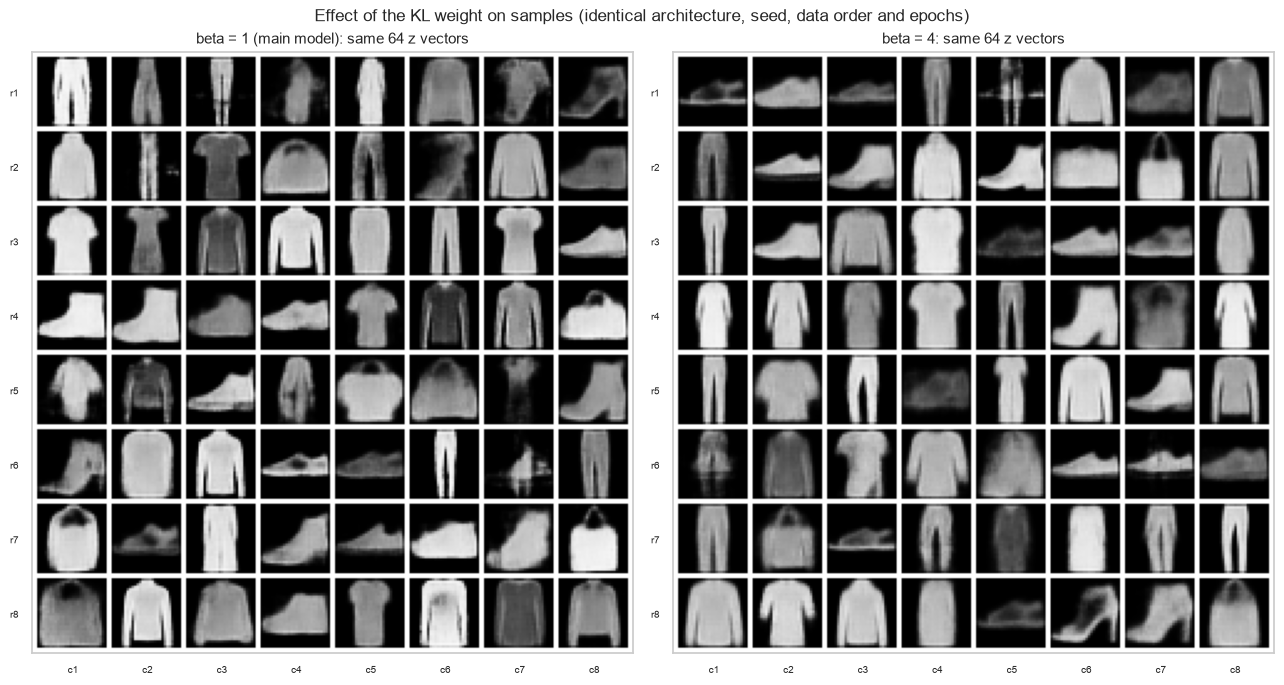

In [18]:
BETA_ALT = 4.0
torch.manual_seed(SEED)
beta_model = ConvVAE(latent_dim=LATENT_DIM).to(device)
history_beta, train_seconds_beta = fit(beta_model, EPOCHS, beta=BETA_ALT, lr=LR, label="beta-VAE")
history_beta.to_csv(f"{RESULTS_DIR}/training_history_beta4.csv", index=False)
torch.save(beta_model.state_dict(), f"{MODEL_DIR}/beta4_vae_fashionmnist.pt")
beta_model.eval()

torch.manual_seed(SEED)
b_total, b_recon, b_kl = run_epoch(beta_model, test_loader, beta=BETA_ALT)
b_mse, b_bce = recon_errors(beta_model, X_test)
with torch.no_grad():
    samples_beta = beta_model.decode(z_samples).cpu()
nn_idx_beta, nn_dist_beta = nearest_train(samples_beta)
beta_class_counts = np.bincount(y_train_full[nn_idx_beta].numpy(), minlength=10)
active_dims_beta = int((kl_per_dim(beta_model, X_test) > 0.01).sum())

comparison = pd.DataFrame({
    "beta = 1 (main)": [test_mse.mean(), test_bce.mean(), test_kl, active_dims, (sample_class_counts > 0).sum(), nn_dist.mean()],
    "beta = 4": [b_mse.mean(), b_bce.mean(), b_kl, active_dims_beta, (beta_class_counts > 0).sum(), nn_dist_beta.mean()],
}, index=["test recon MSE", "test recon BCE (nats)", "test KL (nats)", "active latent dims (of 16)",
          "classes covered by 64 samples", "mean NN L2 of samples"])
print(comparison.round(4).to_string())
print("\nSamples per nearest-neighbour class, beta = 4:")
print(pd.Series(beta_class_counts, index=CLASS_NAMES).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))
for ax, imgs, name in [(axes[0], samples, "beta = 1 (main model)"), (axes[1], samples_beta, f"beta = {BETA_ALT:g}")]:
    grid = torchvision.utils.make_grid(imgs, nrow=8, padding=2, pad_value=1.0)
    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set_title(f"{name}: same 64 z vectors", fontsize=11)
    ax.set_xticks([30 * j + 16 for j in range(8)], [f"c{j + 1}" for j in range(8)], fontsize=7)
    ax.set_yticks([30 * i + 16 for i in range(8)], [f"r{i + 1}" for i in range(8)], fontsize=7)
    ax.grid(False)
fig.suptitle("Effect of the KL weight on samples (identical architecture, seed, data order and epochs)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/beta_vae_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


### What changing beta did
- **Trade-off confirmed:** with $\beta = 4$ the test KL falls from **14.76 to 6.78** nats and only **6** latent dimensions stay active (vs **9** for $\beta = 1$). Reconstruction gets worse: test MSE rises from **0.0124 to 0.0176** (+42%) and BCE from 219.2 to 231.2 nats. This is the reconstruction-vs-regularisation trade-off described by Higgins et al. (2017).
- **Sample quality:** the $\beta = 4$ grid (right) is visibly blurrier and more "average". Tops become plain rounded shapes, and faint, ghost-like shoes appear (r1 c1, r1 c3, r3 c5, r6 c8). Trousers become more common (12 of 64 nearest-neighbour labels vs 6). Artefacts do not disappear either: r1 c5 has a horizontal streak and r6 c1 is a smeared mix.
- **Lower nearest-neighbour distance (2.89 vs 3.35)** does **not** mean more memorisation here. Blurrier, prototype-like images are closer in pixel L2 to many training images at once.
- Because the same $z$ vectors decode to completely different items in the two models, each model organises its latent space in its own way. For this project's goal (realistic samples), $\beta = 1$ is the better choice.


## Optional extra 2: 2-D view of the latent space (t-SNE)
t-SNE projects the 16-dimensional encoder means of 3,000 test images to 2-D for visualisation only. Distances between far-apart clusters are not meaningful in t-SNE, but which points end up next to each other is.

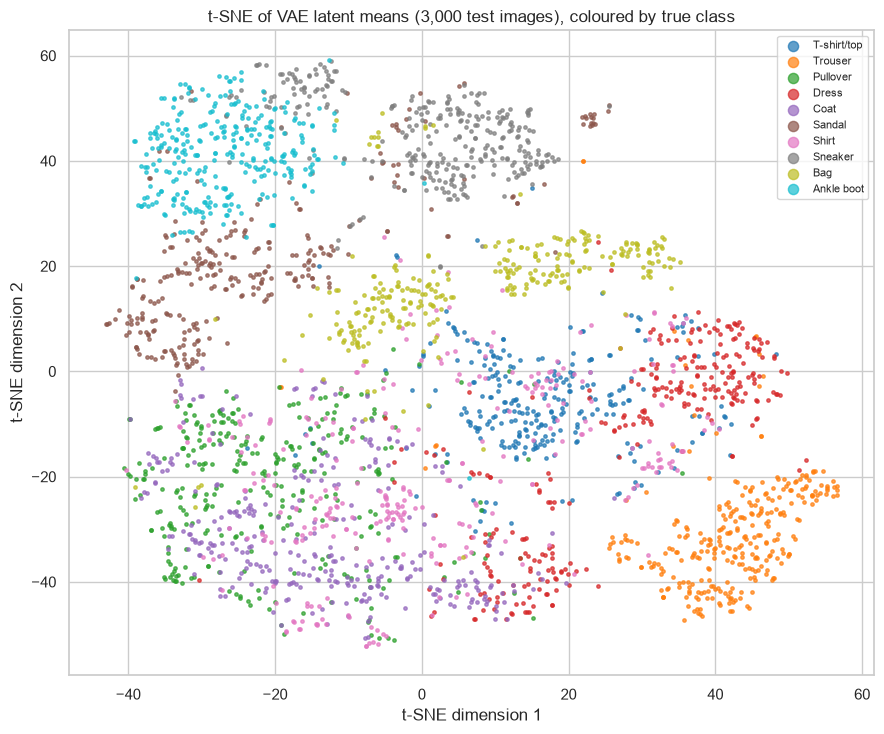

Share of each point's 10 nearest latent neighbours with the same class:
Shirt          0.443
Pullover       0.526
Coat           0.553
T-shirt/top    0.625
Dress          0.668
Sandal         0.708
Bag            0.797
Sneaker        0.840
Ankle boot     0.867
Trouser        0.891


In [19]:
tsne_idx = np.random.default_rng(SEED).choice(len(X_test), size=3000, replace=False)
with torch.no_grad():
    mu_test = model.encode(X_test[tsne_idx].to(device))[0].cpu().numpy()
emb = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(mu_test)

fig, ax = plt.subplots(figsize=(9, 7.5))
palette = sns.color_palette("tab10", 10)
for c in range(10):
    m = test_labels[tsne_idx] == c
    ax.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.7, color=palette[c], label=CLASS_NAMES[c])
ax.set_title("t-SNE of VAE latent means (3,000 test images), coloured by true class")
ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.legend(markerscale=3, fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/latent_tsne.png", dpi=150, bbox_inches="tight")
plt.show()

# Simple numeric check of class mixing in latent space: 10-NN class agreement in the 16-D latent means
d = torch.cdist(torch.tensor(mu_test), torch.tensor(mu_test))
d.fill_diagonal_(float("inf"))
knn = d.topk(10, largest=False).indices.numpy()
agree = (test_labels[tsne_idx][knn] == test_labels[tsne_idx][:, None]).mean(axis=1)
knn_agree = pd.Series(agree).groupby(np.array(CLASS_NAMES)[test_labels[tsne_idx]]).mean().sort_values()
print("Share of each point's 10 nearest latent neighbours with the same class:")
print(knn_agree.round(3).to_string())


### What the latent space looks like
- **Clear clusters for distinct shapes:** trousers (bottom right) and the three footwear classes (top left: ankle boot, sandal, sneaker) form compact, well-separated groups, with sandals as a looser group next to the ankle boots and sneakers. Bags form two separate clusters.
- **Overlap between the tops classes:** pullover, coat and shirt overlap heavily in the bottom-left region, and shirts are also scattered among T-shirts and dresses. The 10-nearest-neighbour agreement in the 16-D latent space confirms this: **Shirt 0.443, Pullover 0.526, Coat 0.553**, against **Trouser 0.891** and **Ankle boot 0.867**.
- This explains the class-blending failures above. Random $z$ values that land in the overlap region decode to garments that mix shirt, pullover and coat features.


In [20]:
# Save every number used in the written report
metrics = {
    "seed": SEED, "device": str(device), "torch_version": torch.__version__,
    "n_train": len(X_tr), "n_val": len(X_val), "n_test": len(X_test),
    "latent_dim": LATENT_DIM, "batch_size": BATCH_SIZE, "lr": LR, "epochs": EPOCHS, "beta": BETA,
    "n_params": n_params, "train_minutes": train_seconds / 60,
    "model_file_mb": os.path.getsize(MODEL_PATH) / 1e6,
    "history": history.to_dict(orient="list"),
    "test_total": test_total, "test_recon_bce_sampled": test_recon, "test_kl": test_kl,
    "test_mse": float(test_mse.mean()), "test_bce": float(test_bce.mean()),
    "per_class_mse": per_class.mse.to_dict(), "per_class_bce": per_class.bce.to_dict(),
    "active_dims": active_dims, "kl_per_dim_sorted": kl_dim[order].tolist(), "active_dims_beta": active_dims_beta,
    "recon_pick_mse": {f"#{k + 1} {CLASS_NAMES[test_labels[i]]}": float(test_mse[i]) for k, i in enumerate(pick)},
    "nn_dist_generated": nn_dist.tolist(), "nn_dist_reference_test": ref_dist.tolist(),
    "nn_class_first8": [CLASS_NAMES[c] for c in nn_class[:8]],
    "nn_class_grid": np.array(SHORT)[nn_class].reshape(8, 8).tolist(),
    "sample_class_counts": sample_class_counts.to_dict(),
    "beta_alt": BETA_ALT, "beta_train_minutes": train_seconds_beta / 60,
    "beta_history_last": history_beta.iloc[-1].to_dict(),
    "beta_test_mse": float(b_mse.mean()), "beta_test_bce": float(b_bce.mean()), "beta_test_kl": b_kl,
    "beta_nn_dist_mean": float(nn_dist_beta.mean()),
    "beta_class_counts": dict(zip(CLASS_NAMES, beta_class_counts.tolist())),
    "knn_agreement": knn_agree.to_dict(),
}
with open(f"{RESULTS_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)
print(f"Saved {RESULTS_DIR}/metrics.json")
print("Figures:", sorted(os.listdir(FIG_DIR)))

Saved results/metrics.json
Figures: ['beta_vae_comparison.png', 'class_distribution.png', 'data_samples.png', 'generated_samples.png', 'latent_interpolation.png', 'latent_kl_per_dim.png', 'latent_tsne.png', 'loss_curves.png', 'nearest_neighbors.png', 'per_class_error.png', 'reconstructions.png']


## References
- Carlini, N., Hayes, J., Nasr, M., Jagielski, M., Sehwag, V., Tramèr, F., Balle, B., Ippolito, D., & Wallace, E. (2023). Extracting training data from diffusion models. In *Proceedings of the 32nd USENIX Security Symposium* (pp. 5253–5270). USENIX Association. https://www.usenix.org/conference/usenixsecurity23/presentation/carlini
- Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. In *Advances in Neural Information Processing Systems 30*. Curran Associates. https://proceedings.neurips.cc/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html
- Higgins, I., Matthey, L., Pal, A., Burgess, C., Glorot, X., Botvinick, M., Mohamed, S., & Lerchner, A. (2017). beta-VAE: Learning basic visual concepts with a constrained variational framework. In *Proceedings of the 5th International Conference on Learning Representations (ICLR 2017)*. https://openreview.net/forum?id=Sy2fzU9gl
- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. In *Proceedings of the 2nd International Conference on Learning Representations (ICLR 2014)*. https://doi.org/10.48550/arXiv.1312.6114
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: A novel image dataset for benchmarking machine learning algorithms* (arXiv:1708.07747). arXiv. https://doi.org/10.48550/arXiv.1708.07747


## Summary
This notebook trained a convolutional VAE (1,688,289 parameters, 16-D latent space, BCE + KL loss, Adam with lr 1e-3, batch size 128, 25 epochs) on 55,000 real Fashion-MNIST product photos to generate new 28x28 grayscale clothing images and learn a smooth latent space of clothing styles. On the 10,000 test images it reached a negative ELBO of 237.83 nats per image and a reconstruction MSE of 0.0124. Its 64 random samples cover all 10 classes with recognisable silhouettes, and the sneaker-to-ankle-boot interpolation changes shape gradually and plausibly. Training was stable and converged in about 2.4 CPU minutes with a final train-validation gap of only 1.10 nats; the main challenge was the reconstruction-KL trade-off, which left only 9 of 16 latent dimensions active and which the beta = 4 run made explicit (KL fell from 14.76 to 6.78 nats while MSE rose from 0.0124 to 0.0176). The main failure modes are blur and lost fine detail (logos, plaid and prints vanish, e.g. the "Lee" pullover reconstruction with MSE 0.030), blending of shirts, pullovers and coats, which are the most mixed classes in latent space, and thin-strap sandals, which have the highest per-class MSE (0.0193) and appear in only 1 of 64 samples. A nearest-neighbour check found no sign of memorised training images (mean L2 3.35 for samples vs 3.34 for real test images), but the evaluation is mainly qualitative, because no sample-quality metric such as FID (Heusel et al., 2017) was computed and the outputs are limited to low-resolution grayscale catalogue items.
